# 🚀 03. Supervised Deep Learning, Hybrid Modeling, and Baselines
### Project: XAI System in Banking: AI Anomaly-Driven Credit Card Fraud Detection and Interpretation
**Objective:** Compare supervised Tabular Deep ResNet (trained with Focal Loss) against the Anomaly-Augmented Hybrid Pipeline and industry-standard Gradient Boosted Decision Trees (XGBoost & LightGBM).

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
import joblib, torch

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

from src.data.preprocessing import DataPipeline
from src.evaluation.evaluator import ModelEvaluator
from src.utils.device import get_device

device = get_device("auto")
print(f"Device: {device}")


Device: cpu


## 1. Focal Loss Formulation
Standard Binary Cross-Entropy struggles with 578:1 imbalance because the millions of easy negatives overwhelm the gradients.
$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$
Where $\gamma = 2.0$ downweights easy examples and $\alpha = 0.25$ balances positive/negative class weights.

In [2]:
pipeline = DataPipeline(processed_dir=str(ROOT_DIR / "data/processed"))
data = pipeline.load_processed()
# Load Model Comparison Summary Table
summary_path = ROOT_DIR / "results/tables/model_comparison.csv"
if summary_path.exists():
    df_results = pd.read_csv(summary_path)
    print("Trained Benchmark Results on Unseen Test Set:")
    df_table = df_results[["Model", "AUPRC", "ROC-AUC", "F1-Score", "F2-Score", "Recall", "Precision", "Total Loss ($)"]]
    print(df_table.to_string(index=False))
else:
    print("Model comparison table not found. Run python scripts/evaluate.py to generate benchmarks.")


Trained Benchmark Results on Unseen Test Set:
                     Model  AUPRC  ROC-AUC  F1-Score  F2-Score  Recall  Precision  Total Loss ($)
                   XGBoost 0.8245   0.9718    0.8276    0.8174  0.8108     0.8451          7110.0
   Supervised Deep Tabular 0.6576   0.9165    0.7436    0.7672  0.7838     0.7073          8240.0
       Logistic Regression 0.6463   0.9639    0.6425    0.7470  0.8378     0.5210          6570.0
Hybrid (Anomaly + Deep DL) 0.5949   0.9213    0.7226    0.7427  0.7568     0.6914          9250.0
                  LightGBM 0.4551   0.9314    0.5438    0.6720  0.7973     0.4126          8340.0
       Autoencoder (Alone) 0.1911   0.9493    0.2378    0.3917  0.6892     0.1437         14540.0
          Isolation Forest 0.1033   0.9407    0.2308    0.2791  0.3243     0.1791         26100.0


## 2. Precision-Recall Curves
Precision-Recall curves are the gold standard for severely imbalanced fraud benchmarks.

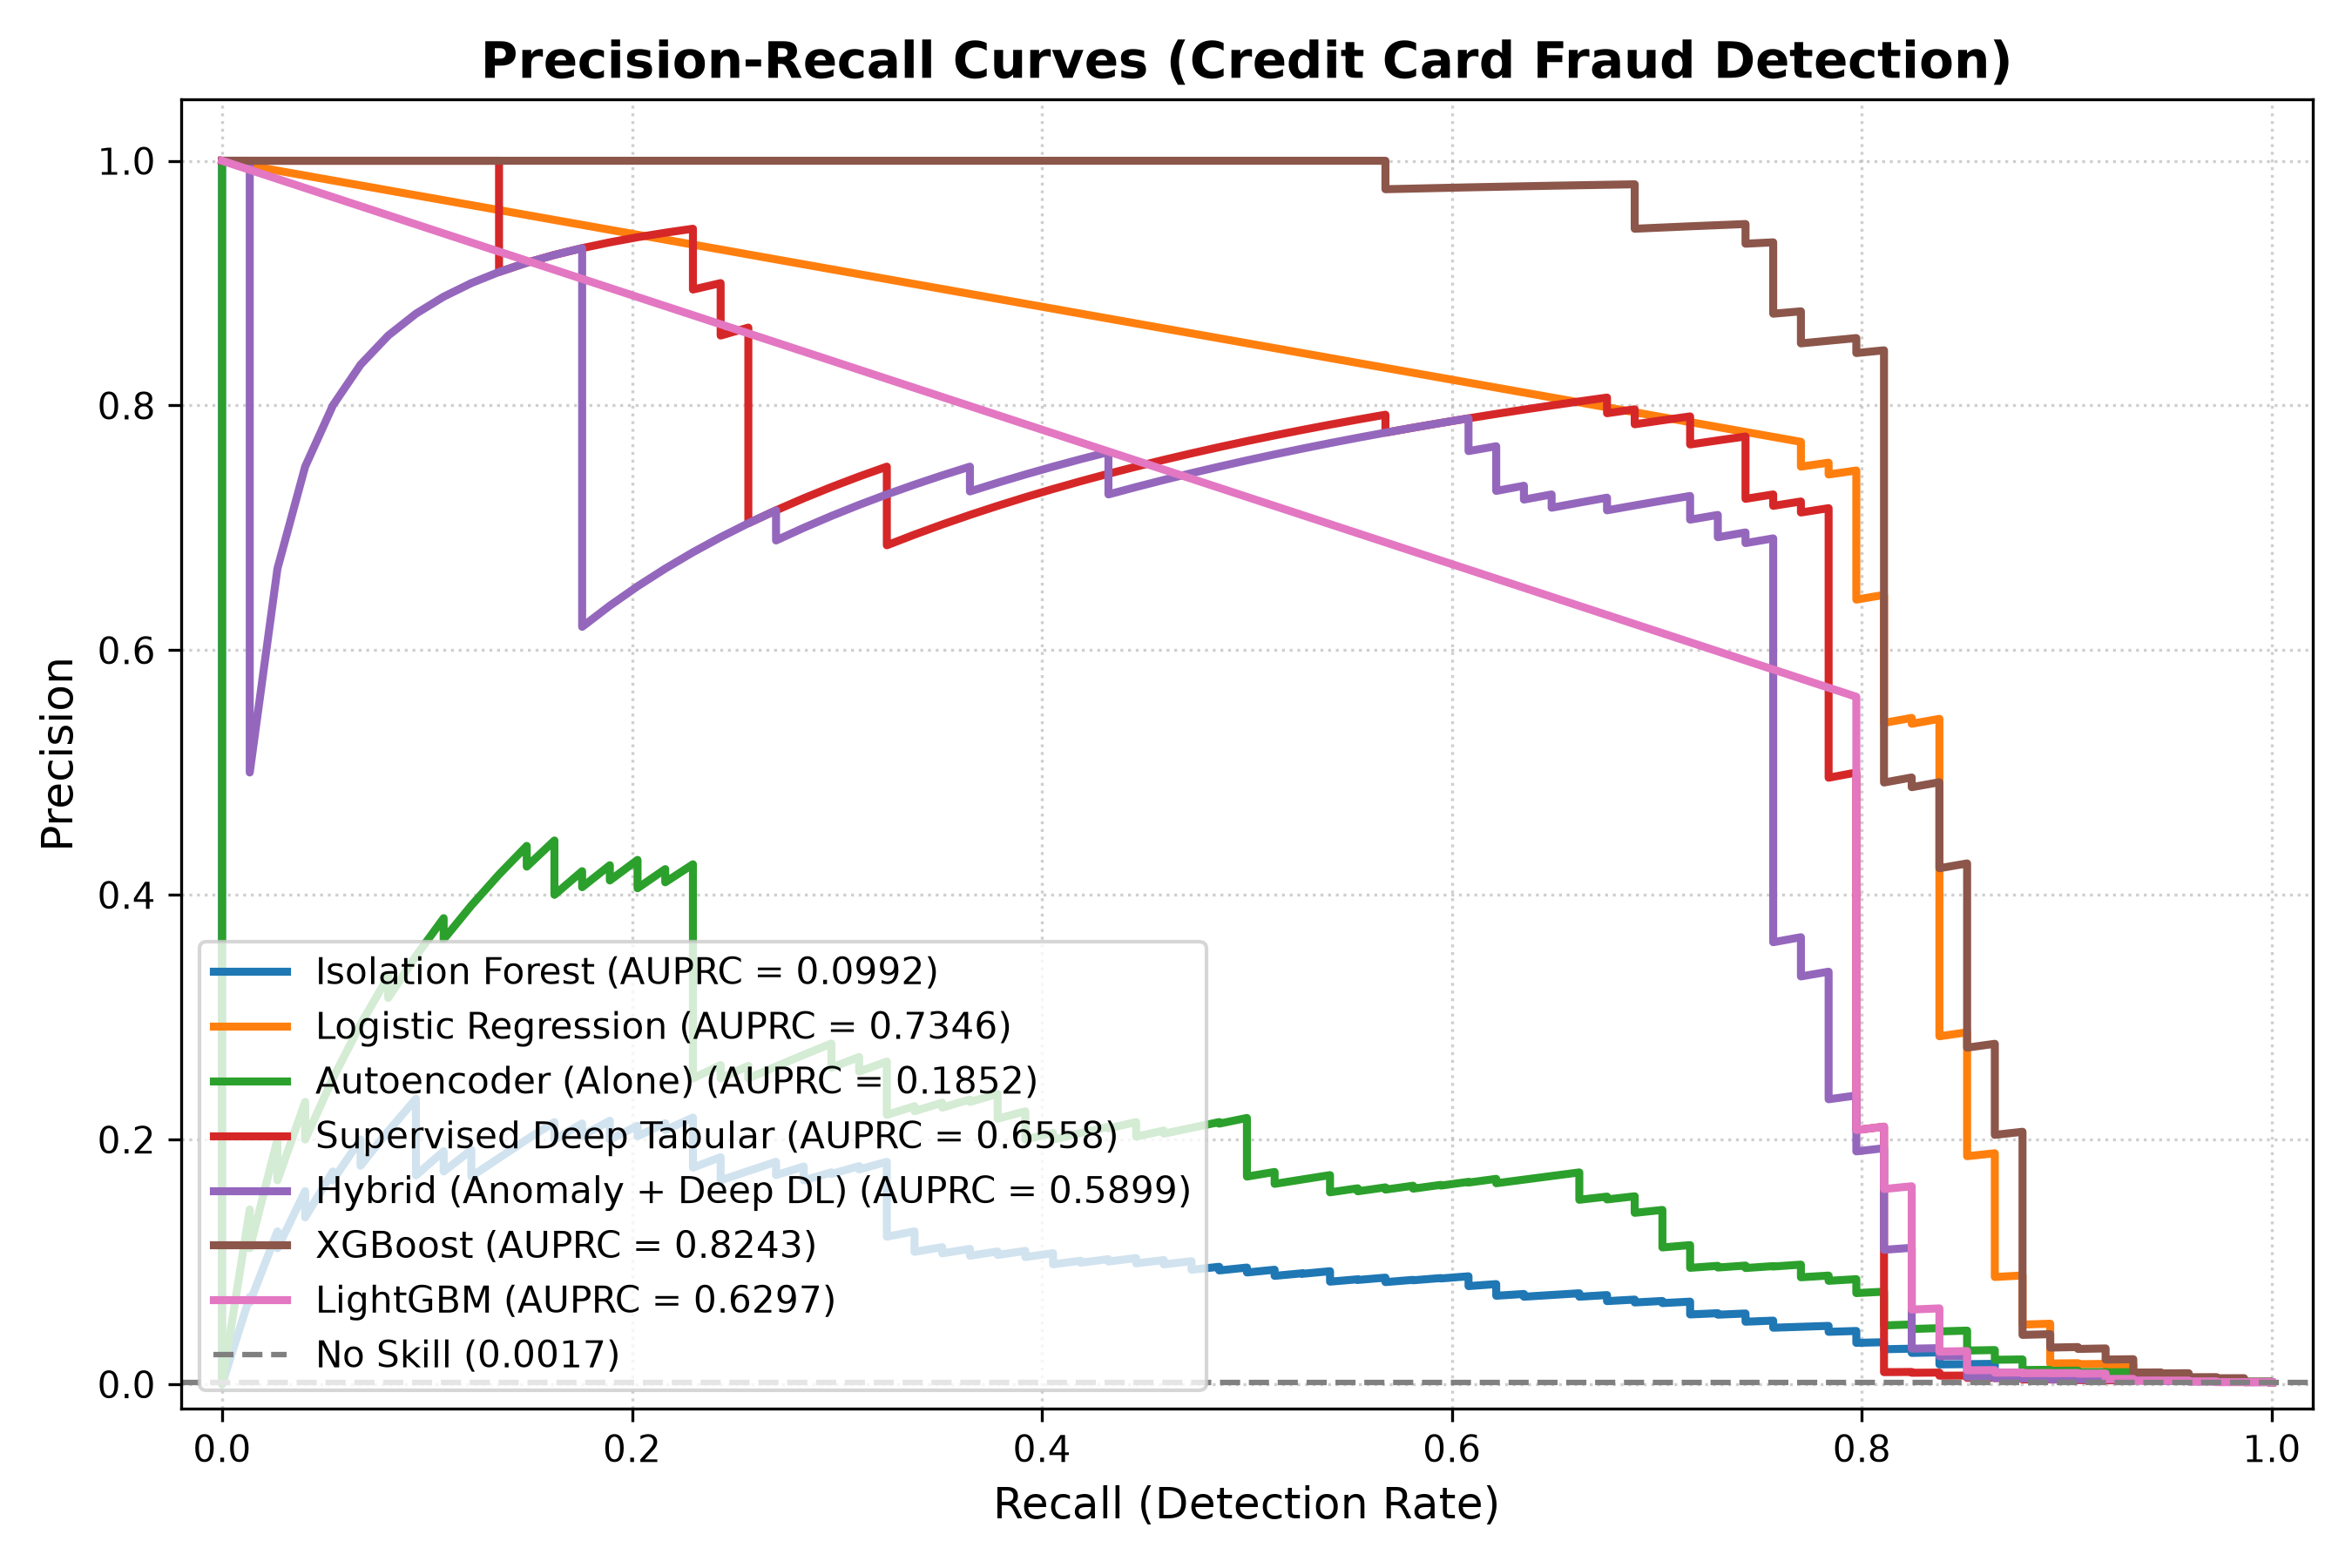

In [3]:
pr_img_path = ROOT_DIR / "results/figures/pr_curves.png"
if pr_img_path.exists():
    display(Image(filename=str(pr_img_path)))
else:
    print("PR curve plot not found.")


## 3. Financial Cost Analysis
Financial loss model:
$$\text{Total Financial Cost} = \text{FP} \times \$10 + \text{FN} \times \$500$$
We compare the cost incurred by each architecture.

/tmp/ipykernel_7998/389443223.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x="Model", y="Total Loss ($)", palette="viridis")


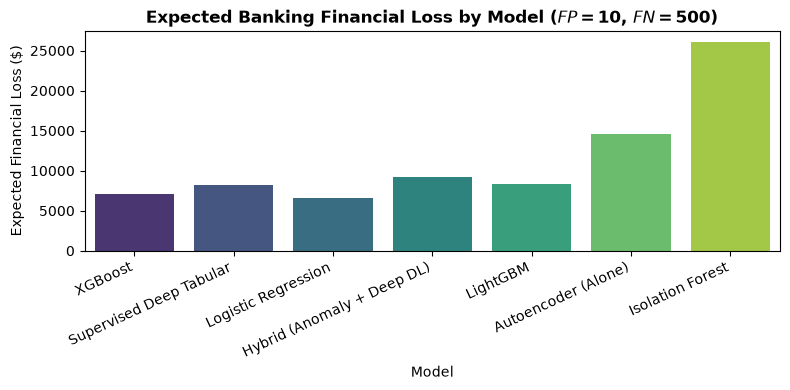

In [4]:
if summary_path.exists():
    plt.figure(figsize=(8, 4))
    sns.barplot(data=df_results, x="Model", y="Total Loss ($)", palette="viridis")
    plt.xticks(rotation=25, ha="right")
    plt.title("Expected Banking Financial Loss by Model ($FP=$10, $FN=$500)", fontsize=12, fontweight="bold")
    plt.ylabel("Expected Financial Loss ($)")
    plt.tight_layout()
    plt.show()